# Sample Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

%matplotlib inline

In [2]:
processed_path = '../data/processed/processed.parquet'

df = pd.read_parquet(processed_path)

In [3]:
print(df.columns)
print(df.dtypes)

Index(['firm_id', 'rating', 'former', 'emp_type', 'tenure', 'year', 'date',
       'number of reviews', 'cons', 'job'],
      dtype='str')
firm_id                       int64
rating                         int8
former                         int8
emp_type                   category
tenure                     category
year                          int16
date                 datetime64[us]
number of reviews             int64
cons                            str
job                             str
dtype: object


In [4]:
means = df.groupby("former")["rating"].mean()
print(means[1] - means[0])

-0.4999101794668488


In [5]:
counts = df.groupby(["firm_id", "former"]).size().unstack()
large = counts[(counts[0] >= 5000) & (counts[1] >= 1000)]
len(large)

60

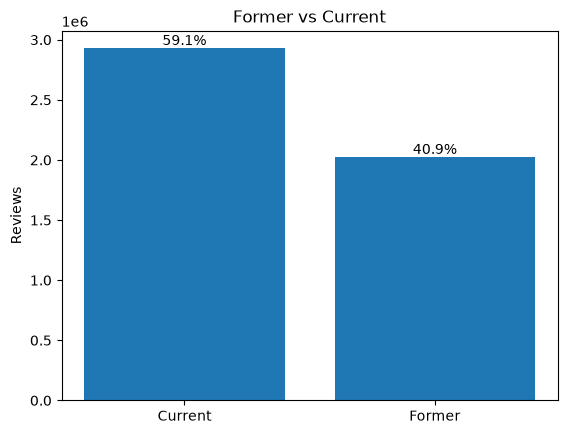

In [6]:
counts = df["former"].map({1: "Former", 0: "Current"}).value_counts()
pct = counts / counts.sum() * 100

bars = plt.bar(counts.index, counts.values)
plt.bar_label(bars, labels=[f"{p:.1f}%" for p in pct])
plt.title("Former vs Current")
plt.ylabel("Reviews")
plt.show()

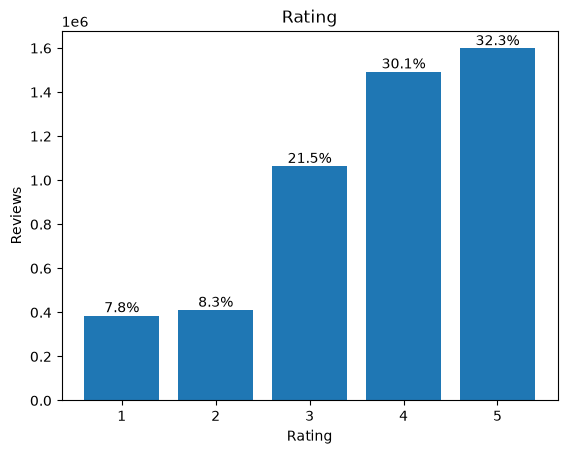

In [7]:
counts = df["rating"].value_counts().sort_index()
pct = counts / counts.sum() * 100

bars = plt.bar(counts.index, counts.values)
plt.bar_label(bars, labels=[f"{p:.1f}%" for p in pct])
plt.title("Rating")
plt.xlabel("Rating")
plt.ylabel("Reviews")
plt.show()

In [8]:
print(f"Mean: {df["rating"].mean()} \nMedian: {df["rating"].median()}")

Mean: 3.708372589864462 
Median: 4.0


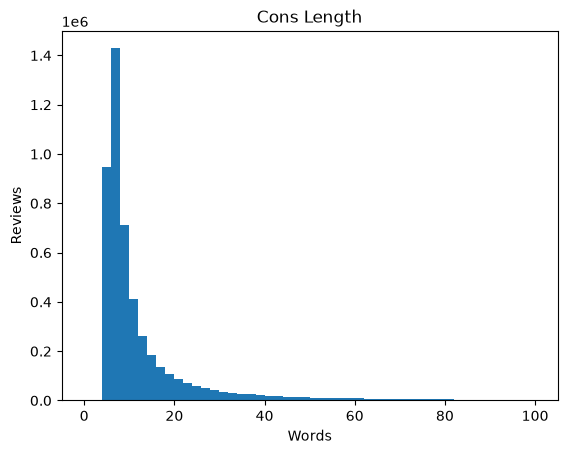

In [9]:
cons_len = df["cons"].str.split().str.len()

plt.hist(cons_len, bins=50, range=(0, 100))
plt.title("Cons Length")
plt.xlabel("Words")
plt.ylabel("Reviews")
plt.show()

In [10]:
print(f"Mean: {cons_len.mean()} \nMedian: {cons_len.median()}")

Mean: 15.276002693146717 
Median: 8.0


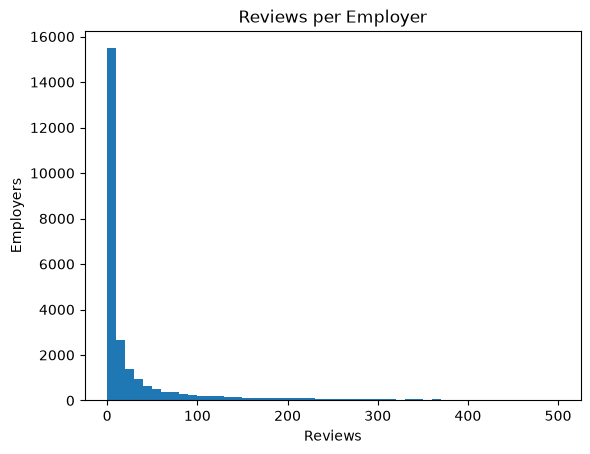

In [11]:
per_firm = df["firm_id"].value_counts()

plt.hist(per_firm, bins=50, range=(0, 500))
plt.title("Reviews per Employer")
plt.xlabel("Reviews")
plt.ylabel("Employers")
plt.show()

In [12]:
print(f"Mean: {per_firm.mean()} \nMedian: {per_firm.median()}")

Mean: 178.53231390652047 
Median: 7.0


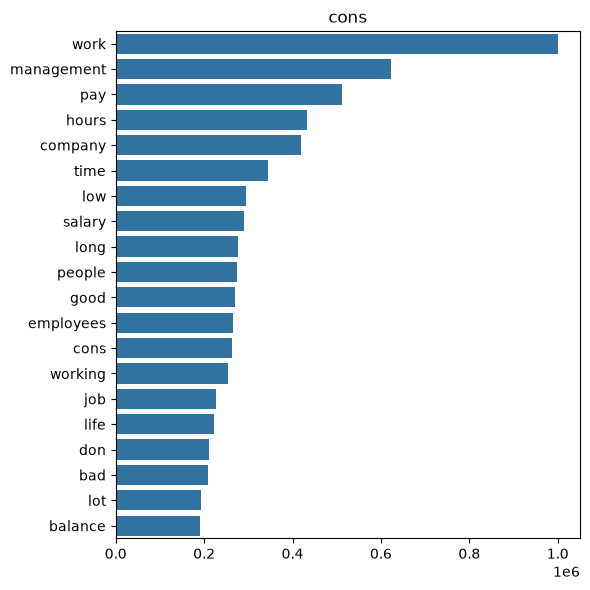

In [13]:
def top_words(series, n=20):
    counter = Counter()
    for tokens in series.dropna().str.lower().str.findall(r"[a-z]+"):
        counter.update(w for w in tokens if len(w) > 1 and w not in ENGLISH_STOP_WORDS)
    return counter.most_common(n)

words, counts = zip(*top_words(df["cons"]))

plt.figure(figsize=(6, 6))
sns.barplot(x=list(counts), y=list(words))
plt.title("cons")
plt.tight_layout()
plt.show()

In [14]:
print(f"Mean: {cons_len.mean()} \nMedian: {cons_len.median()}")

Mean: 15.276002693146717 
Median: 8.0


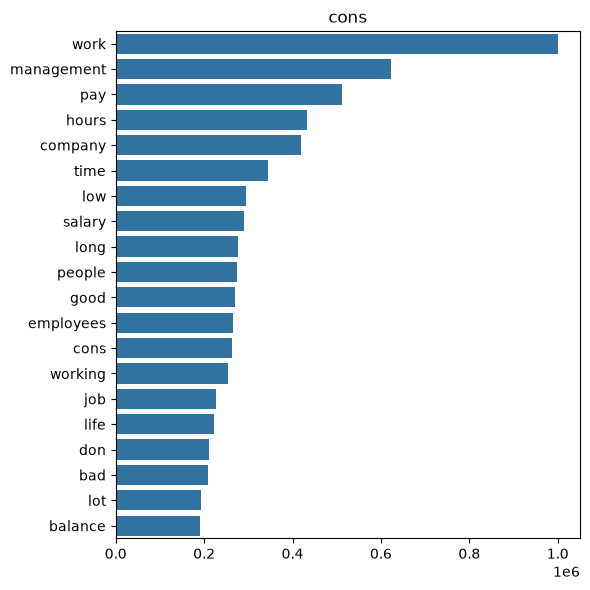

In [15]:
def top_words(series, n=20):
    counter = Counter()
    for tokens in series.dropna().str.lower().str.findall(r"[a-z]+"):
        counter.update(w for w in tokens if len(w) > 1 and w not in ENGLISH_STOP_WORDS)
    return counter.most_common(n)

words, counts = zip(*top_words(df["cons"]))

plt.figure(figsize=(6, 6))
sns.barplot(x=list(counts), y=list(words))
plt.title("cons")
plt.tight_layout()
plt.show()

In [16]:
sd = df["rating"].std()
n_star = int(np.ceil(2 * (1.96 * sd / 0.25) ** 2))

counts = df.groupby(["firm_id", "former"]).size().unstack(fill_value=0)
enough = counts.min(axis=1) >= n_star

print(f"SD: {sd:.2f}")
print(f"n* per group: {n_star}")
print(f"Employers without enough reviews: {(~enough).mean():.1%}")
print(f"Reviews covered: {counts[enough].sum().sum() / counts.sum().sum():.1%}")

SD: 1.22
n* per group: 183
Employers without enough reviews: 93.3%
Reviews covered: 80.1%
